---

<br>

# MODULE 6: MODEL ASSUMPTIONS

<br>

---

In this section we'll cover the **assumptions of linear regression** models which should be checked and met to ensure that the meodel's predictions and interpretation are valid.

<br>

## Topics We'll Cover

>- Assumptions Overview
>
>- Linearity
>
>- Independence of Errors
>
>- Normality of Errors
>
>- No Perfect Multicolinearity
>
>- Equal Variance of Errors
>
>- Outliers & Influence

<br>

## Goals for This Section

>- Review the assumptions of linear regression models
>
>- Lear to diagnose and fix violations to each assumption using Python
>
>- Assess the influence of outliers on a regression model, and learn methods for dealing with them
>

<br><br>

>---
>
>There are few key **assumptions of linear regression** models that can be violated, leading to unrelaible predictions and interpretations.
>
>- *if the goal is `inference`*, these all need to be checked rigorously.
>
>- *if the goal is `prediction`*, some of these can be relaxed
>
>---

<br>

<span style='color:gray'>
    
>---
>
>It is importan to remember the following assumptions for `interviews & better comprehension` on linear regression:
>
>   1. `Linearity`: A linear relationship exists between the target and features.
>
>   2. `Independence of Errors`: The residuals are not correlated.
>
>   3. `Normality of Errors`: The residuals are approximately normally distribuited.
> 
>   4. `No perfect Multicolinearity`: The features aren't perfectly correlated with each other.
>
>   5. `Equal Variance of Errors`: The spread of residuals is consistent across predictions.
>
>---

<br>



<br><br>

---

# Linear Relationship (*Linearity*)

<br>

---

## 1. Understanding Linearity

Linear Regression assumes that the **expected target value can be expressed as a linear combination of the model's coefficients and its features**.

- If the model fails to capture the underlying feature-target relationship, predictions may become inaccurate.

- Linearity does **not** mean every original feature must have a straight-line relationship with the target.

- A Linear Regression model can represent certain non-linear relationships by using transformed features, such as polynomial terms.

<br>

## 2. Diagnosing Linearity

We can investigate potential linear relationship violations using:

1. `Scatterplots`: Examine the relationship between individual features and the target. **Curved patterns may indicate that a simple linear term is insufficient**.

2. `Residual Plots`: Residuals should ideally be randomly scattered around zero, without systematic patterns. **Curved residual patterns can indicate a misspecified functional relationship**.

<br>
<div style="background-color:rgba(241, 196, 15, 0.15); border-left: 5px solid #f1c40f; padding: 15px; border-radius: 5px;">
  <strong style="color: #f1c40f;">WARNING:</strong> A non-linear relationship between an original feature and the target does not automatically violate linearity if the model includes appropriate transformations.
</div>

<br>

---

## 3. Fixing Non-Linear Relationships

A common solution is to apply **Feature Transformations**, such as:

- **Polynomial Features:** $x^2$, $x^3$, etc.

- **Logarithmic Transformations:** $\log(x)$, for positive values of $x$.

- **Other transformations:** Depending on the underlying relationship and the data distribution.

>---
>
>### Example: Diamond Carat vs. Price
>
>Suppose the relationship between diamond weight (`carat`) and `price` is approximately quadratic.
>
>**Original Linear Regression Model:**
>
>$$
\hat{y} = \beta_0 + \beta_1(\text{carat})
$$
>
>This model may underfit because it cannot adequately capture the curved relationship.
>
>**Transformed Linear Regression Model:**
>
>$$
\hat{y} = \beta_0 + \beta_1(\text{carat}^2)
$$
>
>**By creating a new feature**: We may obtain a more linear relationship between `carat_sq` and `price`, improving model fit and potentially predictive performance.
>
>```python
>df["carat_sq"] = df["carat"] ** 2
>```
>
><br>
>
>
>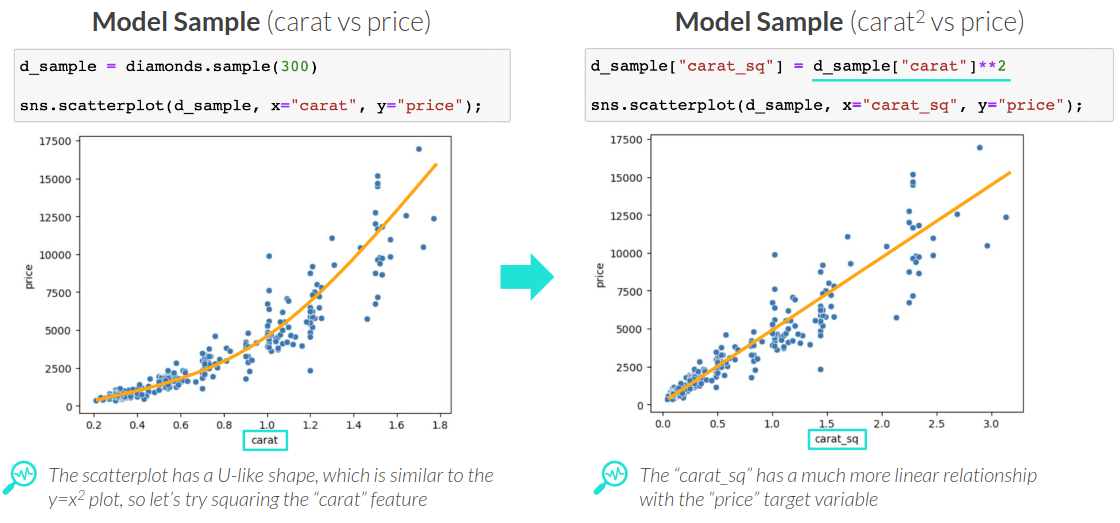
>
>---


<br>

---

### <span style='color:red'>4. Are We Losing Information by Transforming Features?

**Not necessarily. Feature Transformation changes how the information is represented, rather than automatically destroying it.**

Consider the following example:

>---
>
>| Original Feature (`carat`) | Transformed Feature (`carat²`) | Target (`price`) |
>|---:|---:|---:|
>| 0.5 | 0.25 | 500 |
>| 1.0 | 1.00 | 2,000 |
>| 1.5 | 2.25 | 4,500 |
>| 2.0 | 4.00 | 8,000 |
>| 2.5 | 6.25 | 12,500 |
>
>The relationship follows:
>
>$$
\text{price} = 2000 \times \text{carat}^2
$$
>
>**Key observations:**
>
>- The target values remain unchanged.
>- No new observations are invented.
>- The transformed feature provides a different mathematical representation of the original data.
>- Since `carat` is strictly positive, the original values can be recovered using:
>
>$$
\text{carat} = \sqrt{\text{carat\_sq}}
$$
>
><br>
>
><div style="background-color:rgba(241, 196, 15, 0.15); border-left: 5px solid #f1c40f; padding: 15px; border-radius: 5px;">
  <strong style="color: #f1c40f;">WARNING:</strong> 
>Squaring positive `carat` values does not inherently result in information loss. **However, not all transformations preserve information.**
>
>- For example, squaring a feature containing both positive and negative values removes the original sign.
></div>
>
><br>
>
>---

<br>

---

### <span style='color:red'>5. Why Is It Still Called Linear Regression?

**A Linear Regression model must be linear in its coefficients $\LARGE (\beta)$, not necessarily in its original features.**

All three models below are linear in their coefficients:

>**Simple Linear Regression:** 
>
>$$\LARGE \hat{y} = \beta_0 + \beta_1 x$$
>
>**Linear Regression with a Squared Feature:**
>
>$$\LARGE \hat{y} = \beta_0 + \beta_1 x^2 $$
>
>**Polynomial Regression (Degree 2):**
>
>$$\LARGE  \hat{y} = \beta_0 + \beta_1 x + \beta_2 x^2 $$
>
>- Even though the last two models describe non-linear relationships with the original feature, they remain **linear models with respect to their coefficients**.
>
>- We can also preserve both the original and transformed features:
>
><br>
>
>```python
>df["carat_sq"] = df["carat"] ** 2
>
>X = df[["carat", "carat_sq"]]
>y = df["price"]
>```
>
><br>
>
>This allows the model to learn the contribution of both terms.
>
>
>
><div style="background-color:rgba(241, 196, 15, 0.15); border-left: 5px solid #f1c40f; padding: 15px; border-radius: 5px;">
  <strong style="color: #f1c40f;">Does Feature Transformation Always Improve Predictions?</strong> <br><br>No. **Transformations must be validated experimentally.** A useful approach is to compare three models:</div>
>
>| Model | Input Features | Purpose |
>|---|---|---|
>| A | `carat` | Baseline linear model |
>| B | `carat_sq` | Model with a squared feature |
>| C | `carat`, `carat_sq` | Second-degree polynomial model |
>
>Compare their performance using:
>
>- **MAE (Mean Absolute Error)**
>- **RMSE (Root Mean Squared Error)**
>- **R² (Coefficient of Determination)**
>- **Residual Plots**
>
>---
>
>- Use validation data or `cross-validation` to select the best transformation, followed by evaluation on an untouched `test set`.
>
>- A transformation may improve performance when it captures the underlying relationship, but unnecessary transformations can introduce complexity, multicollinearity, or overfitting.
>
>---

<br>

---

### 7. Key Takeaways

> - <span style='color:brown'>**Feature Transformation is not the same as falsifying or manipulating observations.** </span> It is a Feature Engineering technique used to represent underlying relationships more effectively.

> - <span style='color:brown'>**Linear Regression requires linearity in the model coefficients</span>, not necessarily in the original feature-target relationship.**

> - <span style='color:brown'>**Transforming features does not automatically imply information loss or better predictions.**</span> The result depends on the transformation, data characteristics, and model specification.

> - <span style='color:brown'>**A more linear-looking scatterplot does not prove that all regression assumptions are satisfied.**</span> Residual analysis and evaluation on unseen data are still necessary.

> - <span style='color:orange'>**ML Engineering Principle:** Choose feature transformations based on their ability to capture meaningful relationships and improve generalization, rather than simply making scatterplots appear more linear.
>
> 
<br><br>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

In [2]:
insurance = pd.read_csv('../datasets/insurance.csv')
insurance.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


<Axes: >

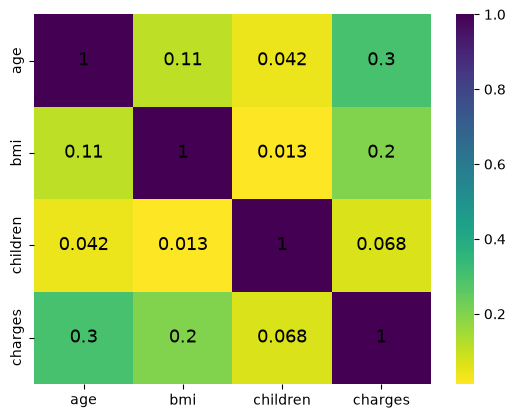

In [5]:
# let's see the correlation between variables
sns.heatmap(insurance.corr(numeric_only=True),
           annot=True, cmap='viridis_r',
           annot_kws={'size': 13, 'color':'black'})

<br>

<div style="background-color:rgba(0, 190, 255, 0.1); border-left: 5px solid #00beff; padding: 15px; border-radius: 5px;">
  <strong style="color: #00beff;">Key Concept:</strong> 
<br><br>

`p-value` helps determine wheter the relationship between the independent variable and the dependent variable is **statistically significant**.

- To test wheter the relationship we observe is meaningful or just due to random chance, we need to start by stating the NULL HIPOTHESIS

- **Null Hypothesis**: It stablishes that there is **no relationship** between the independent variable and the dependent variable:

   - If the `p-value < 0.05`. **We reject the Null Hypothesis**. Because this result suggests a significant relationship between variables.

   - If the `p-value >= 0.05`. **We fail to reject the Null Hypothesis**. Because the observed data may have occurred by chance with no strong evidence of a relationship.
 
</div>

<br>